In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, accuracy_score, f1_score, recall_score, balanced_accuracy_score, precision_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import AdaBoostClassifier
from sklearn.utils.class_weight import compute_sample_weight


## Loading the Data

In [2]:
dt_labeled = pd.read_csv("../../data/clean/decisiontree/dt_labeled.csv")
print(f"The dimensions of dt_labeled are: {dt_labeled.shape}")
print(f"The number of unique participants in this dataset are: {dt_labeled["participant_id"].nunique()}")

The dimensions of dt_labeled are: (8729, 26)
The number of unique participants in this dataset are: 47


In [3]:
y = dt_labeled["low_oxygen"]
groups = dt_labeled["participant_id"]

features_to_remove = [
    "participant_id",
    "cohort",
    "calendarDate",
    "low_oxygen"
]

X = dt_labeled.drop(columns = features_to_remove)

print(y.shape,X.shape)
dt_labeled.head(8).T

(8729,) (8729, 22)


,0,1,2,3,4,5,6,7
participant_id,P2,P2,P2,P2,P2,P2,P2,P2
calendarDate,2026-05-09,2026-05-10,2026-05-11,2026-05-12,2026-05-16,2026-05-14,2026-05-15,2026-05-08
cohort,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03,cohort_03
durationInMs,24120000.0,22620000.0,26040000.0,23940000.0,17940000.0,23880000.0,30600000.0,22260000.0
deepSleepDurationInMs,7020000.0,5280000.0,5700000.0,5640000.0,2160000.0,8820000.0,4260000.0,8460000.0
lightSleepDurationInMs,11700000.0,9660000.0,15240000.0,13140000.0,10980000.0,9120000.0,19620000.0,11580000.0
remSleepInMs,5400000.0,7680000.0,5100000.0,5160000.0,4800000.0,5940000.0,6720000.0,2220000.0
awakeDurationInMs,60000.0,0.0,60000.0,120000.0,120000.0,0.0,60000.0,180000.0
overallSleepScore,79.0,76.0,73.0,81.0,62.0,82.0,84.0,71.0
breathsPerMinute_mean,16.035746,16.368302,16.775543,16.971122,17.72412,16.274823,16.714608,16.747366


## Train/Test Split (by person)

In [4]:
# Train/test split pattern adapted from the scikit-learn StratifiedGroupKFold documentation example
# modified to use a single split and this project's columns.

sgkf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(sgkf.split(X,y,groups = groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print(f"Train size: {len(train_idx)}")
print(f"Test size: {len(test_idx)}")

Train size: 7029
Test size: 1700


## Verifying Test/Train Split Numbers

In [5]:
print(f"People in both sets: {len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))}")
print(f"People in total: {len(set(groups.iloc[train_idx]) | set(groups.iloc[test_idx]))}")
print(f"{len(groups.iloc[train_idx])} + {len(groups.iloc[test_idx])} = {len(groups.iloc[train_idx]) + len(groups.iloc[test_idx])}")

People in both sets: 0
People in total: 47
7029 + 1700 = 8729


In [6]:
print(f"Training set low-oxygen count: {y_train.sum()}")
print(f"Testing set low-oxygen count: {y_test.sum()}")
print(f"Training: {groups.iloc[train_idx].nunique()} people, {len(train_idx)} nights, {(y_train.mean()*100).round(2)}% low oxygen")
print(f"Testing: {groups.iloc[test_idx].nunique()} people, {len(test_idx)} nights, {(y_test.mean()*100).round(2)}% low oxygen")
print("With training and test split such that there are 35 + 12 = 47 (100%) people and 7029 + 1700 = 8729 (100%) nights, " \
"\n we can conclude that no person appears in both sets")

print(len(test_idx)-y_test.sum())

Training set low-oxygen count: 1101
Testing set low-oxygen count: 213
Training: 35 people, 7029 nights, 15.66% low oxygen
Testing: 12 people, 1700 nights, 12.53% low oxygen
With training and test split such that there are 35 + 12 = 47 (100%) people and 7029 + 1700 = 8729 (100%) nights, 
 we can conclude that no person appears in both sets
1487


## Dropping bmrKilocalories (same as Decision Trees: describes the person, not the night)

In [7]:
dropped_X_train, dropped_X_test = X_train.drop(columns="bmrKilocalories"), X_test.drop(columns = "bmrKilocalories")

# AdaBoost

### Stump and Balancing Weights

In [8]:
stump = DecisionTreeClassifier(max_depth=1, random_state=42)
ada = AdaBoostClassifier(estimator=stump, random_state=42)
weights = compute_sample_weight("balanced", y_train)

### Tuning n_estimators and learning_rate (GridSearchCV)

In [9]:
# below code was adapted from https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
# Hyperparameter tuning performed using sklearn's GridSearchCV.
# Candidate parameter values were selected based on sklearn AdaBoostClassifier documentation.

cv = StratifiedGroupKFold(n_splits=5,shuffle=True, random_state=42)

param_grid = {
    'n_estimators': [50,100,200,400,800],
    'learning_rate': [.005, .01,.1,.5,1]
}

grid = GridSearchCV(estimator=ada, param_grid=param_grid, cv=cv, scoring = "balanced_accuracy", n_jobs=-1)

grid.fit(dropped_X_train, y_train, groups=groups.iloc[train_idx],sample_weight=weights)



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",AdaBoostClass...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'learning_rate': [0.005, 0.01, ...], 'n_estimators': [50, 100, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'balanced_accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedGro... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose:

#### Grid Search Results

In [10]:
dropped_df = pd.DataFrame(grid.cv_results_)
dropped_df = dropped_df[["mean_test_score","std_test_score","rank_test_score","param_n_estimators", "param_learning_rate", "split0_test_score", "split1_test_score", "split2_test_score", "split3_test_score", "split4_test_score"]].sort_values("mean_test_score", ascending=False)
dropped_df.head(10)


,mean_test_score,std_test_score,rank_test_score,param_n_estimators,param_learning_rate,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score
8,0.647641,0.072459,1,400,0.010,0.723175,0.580356,0.741454,0.628310,0.564910
10,0.646228,0.071399,2,50,0.100,0.738740,0.562718,0.716144,0.638025,0.575511
4,0.645489,0.070311,3,800,0.005,0.712413,0.580356,0.741454,0.628310,0.564910
0,0.643501,0.071296,4,50,0.005,0.712413,0.588772,0.745077,0.603702,0.567540
3,0.640326,0.072390,5,400,0.005,0.710619,0.587877,0.738813,0.614125,0.550196
7,0.640326,0.072390,5,200,0.010,0.710619,0.587877,0.738813,0.614125,0.550196
2,0.635548,0.076499,7,200,0.005,0.710619,0.588772,0.738360,0.603702,0.536289
6,0.635548,0.076499,7,100,0.010,0.710619,0.588772,0.738360,0.603702,0.536289
1,0.631137,0.072194,9,100,0.005,0.689543,0.588772,0.736925,0.603702,0.536745
5,0.631137,0.072194,9,50,0.010,0.689543,0.588772,0.736925,0.603702,0.536745


### Validation Curve

In [11]:
fit_idx, val_idx = next(cv.split(dropped_X_train,y_train,groups = groups.iloc[train_idx]))
print(len(fit_idx)+len(val_idx))

7029


/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but AdaBoostClassifier was fitted with feature names
  warnings.warn(
/Users/samuelmeaux/Desktop/Machine Learning/Machine Learning Project - Fall 2026/applied-ml-project/.venv/lib/python3.13/site-package

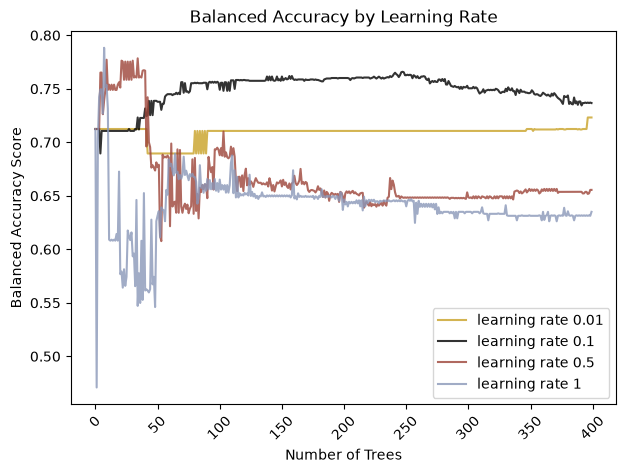

In [12]:


fig, ax = plt.subplots()
ax.set_title("Balanced Accuracy by Learning Rate")
ax.set_ylabel("Balanced Accuracy Score")
ax.set_xlabel("Number of Trees")
plt.xticks(rotation = 45)
plt.tight_layout()

for lr,color in zip([0.01, 0.1, 0.5, 1],["#C9A227", "black", "#9C4438", "#8A97B8"]):
    
    scores = []
    model = AdaBoostClassifier(estimator=stump, n_estimators=400,learning_rate=lr, random_state=42)
    model.fit(dropped_X_train.iloc[fit_idx], y_train.iloc[fit_idx], sample_weight=weights[fit_idx])
    for run in model.staged_predict(dropped_X_train.iloc[val_idx]):
        scores.append(balanced_accuracy_score(y_train.iloc[val_idx],run))
    ax.plot(scores,color = color, alpha=0.8, label=f"learning rate {lr}")
    ax.legend()

plt.savefig("../../images/adaboost/balanced_accuracy_by_learning_rate.png",dpi=150, bbox_inches="tight")


### Final Model (50 Stumps, Learning Rate 0.1)

In [13]:
final_ada = AdaBoostClassifier(estimator=stump, n_estimators=50, learning_rate=0.1, random_state=42)
final_ada.fit(dropped_X_train, y_train, sample_weight=weights)
predictions = final_ada.predict(dropped_X_test)
print(f"The number of nights flagged for 'low oxygen' is: {sum(predictions)} out of {len(dropped_X_test)} - {round(sum(predictions)/len(dropped_X_test)*100,3)}%")


The number of nights flagged for 'low oxygen' is: 820 out of 1700 - 48.235%


#### Confusion Matrix and Results

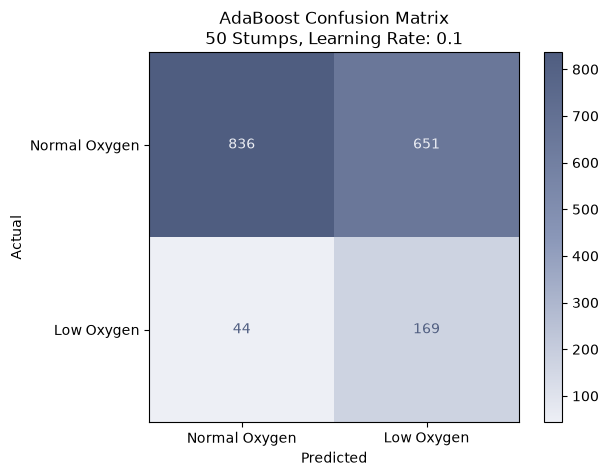

In [14]:
dt_cmap = LinearSegmentedColormap.from_list("site_diverging", ["#EDEFF5", "#8A97B8", "#4F5D80"]) #establish suite of theme colors
cm = confusion_matrix(y_test, predictions)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Normal Oxygen","Low Oxygen"])
disp.plot(cmap = dt_cmap)
disp.ax_.set_xlabel("Predicted")
disp.ax_.set_ylabel("Actual")
disp.ax_.set_title('AdaBoost Confusion Matrix\n50 Stumps, Learning Rate: 0.1');
plt.savefig("../../images/adaboost/adaboost_confusion_matrix.png", dpi=150, bbox_inches="tight")

In [15]:
# Accuracy, F1 Score and Recall Score

accuracy = np.round(accuracy_score(y_test, predictions),3)

# accuracy = (TP + TN)/ total  -- measures the overall correctness aka how many predictions 
# were correct 


f1 = np.round(f1_score(y_test, predictions),3)

# 2 x (Precision x Recall) / (Precision + Recall) -- balances precision and recall and is useful when you care about both false positive and false negatives and also when your data is imbalanced 

recall = np.round(recall_score(y_test, predictions),3)
bas = np.round(balanced_accuracy_score(y_test, predictions),3)
ps = np.round(precision_score(y_test, predictions),3)
baseline= np.round(1 - y_test.mean(),3)

# TP/ (TP + FN ) -- Also called sensitivity or TPR (true positive rate) and this measures how well the model catches the positive class and this is important in cases like disease detection, fraud etc where missing positive is COSTLY!!!

print(f'Accuracy: {accuracy}')
print(f'F1 Score: {f1}')
print(f'Recall Score: {recall}')
print(f'Balanced Accuracy Score: {bas}')
print(f'Precision Score: {ps}')
print(f'Baseline Accuracy if model predicts "normal oxygen" for every observation: {baseline}')

Accuracy: 0.591
F1 Score: 0.327
Recall Score: 0.793
Balanced Accuracy Score: 0.678
Precision Score: 0.206
Baseline Accuracy if model predicts "normal oxygen" for every observation: 0.875


#### Feature Importance

In [16]:
dropped_importance1 = pd.Series(final_ada.feature_importances_, index = dropped_X_train.columns).sort_values(ascending=False)

dropped_importance1

restingHeartRateInBeatsPerMinute    0.515293
minHeartRateInBeatsPerMinute        0.234963
vigorousIntensityDurationInMs       0.169377
breathsPerMinute_min                0.080368
lastNight5MinHigh                   0.000000
moderateIntensityDurationInMs       0.000000
activeKilocalories                  0.000000
steps                               0.000000
maxStressInStressLevel              0.000000
averageStressInStressLevel          0.000000
maxHeartRateInBeatsPerMinute        0.000000
durationInMs                        0.000000
deepSleepDurationInMs               0.000000
breathsPerMinute_max                0.000000
breathsPerMinute_std                0.000000
breathsPerMinute_mean               0.000000
overallSleepScore                   0.000000
awakeDurationInMs                   0.000000
remSleepInMs                        0.000000
lightSleepDurationInMs              0.000000
lastNightAvg                        0.000000
dtype: float64